# Questão 4: O que a CNN aprendeu?

Aqui usamos a CNN treinada na Questão 3 para entender o que ela "enxerga":
- item a: os filtros da primeira camada convolucional e como eles mudam ao longo do treino;
- item b: os mapas de ativação de uma camada intermediária para algumas imagens de teste;
- item c: exemplos que a rede acertou e que errou, com a probabilidade de cada previsão.

Este notebook usa os pesos salvos pela Questão 3 na pasta `checkpoints`. Por isso o notebook da Questão 3 precisa ser executado antes.

## Bibliotecas

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets

# usa a placa de vídeo se tiver, senão usa o processador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

PASTA_DADOS = Path("../data/cifar10")
PASTA_MODELOS = Path("../checkpoints")
PASTA_FIGURAS = Path("../figures/q4")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

Rodando em: cuda


## Funções

Aqui ficam todas as funções que usamos no notebook. Cada uma tem uma explicação curta logo acima.

### fixar_semente
Fixa a "semente" dos sorteios para que os exemplos escolhidos ao acaso sejam sempre os mesmos.

In [2]:
def fixar_semente(semente=42):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)

### bloco_convolucional e CNN
A mesma rede da Questão 3. Precisamos escrever a arquitetura de novo aqui para conseguir carregar os pesos salvos: o arquivo guarda só os números (pesos), não o formato da rede.

In [3]:
def bloco_convolucional(entrada, saida, dropout):
    return nn.Sequential(
        nn.Conv2d(entrada, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.Conv2d(saida, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout(dropout),
    )


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.bloco1 = bloco_convolucional(3, 64, dropout=0.1)
        self.bloco2 = bloco_convolucional(64, 128, dropout=0.2)
        self.bloco3 = bloco_convolucional(128, 256, dropout=0.3)
        self.saida = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 10))

    def forward(self, x):
        return self.saida(self.bloco3(self.bloco2(self.bloco1(x))))

### carregar_modelo
Lê um arquivo de pesos salvo pela Questão 3 e devolve a rede pronta para uso, junto com as informações salvas (época, média e desvio da normalização). Se o arquivo não existir, avisa que é preciso rodar a Questão 3 antes.

In [4]:
def carregar_modelo(nome_arquivo):
    caminho = PASTA_MODELOS / nome_arquivo
    if not caminho.exists():
        raise FileNotFoundError(f"Não achei {caminho}. Execute o notebook da Questão 3 antes deste.")
    salvo = torch.load(caminho, map_location=device, weights_only=True)
    modelo = CNN().to(device)
    modelo.load_state_dict(salvo["pesos"])
    modelo.eval()
    return modelo, salvo

### preparar_imagens
Transforma as imagens (valores de 0 a 255) no formato que a rede espera: canais na frente, pixels entre 0 e 1 e normalização com a mesma média e desvio usados no treino.

In [5]:
def preparar_imagens(imagens, media, desvio):
    x = torch.tensor(imagens, dtype=torch.float32, device=device).permute(0, 3, 1, 2) / 255.0
    return (x - media.to(device).view(1, 3, 1, 1)) / desvio.to(device).view(1, 3, 1, 1)

### prever
Devolve a classe prevista e a probabilidade de cada classe (softmax) para cada imagem.

In [6]:
def prever(modelo, X):
    modelo.eval()
    with torch.no_grad():
        probabilidades = torch.cat([torch.softmax(modelo(X[i:i + 1000]), dim=1) for i in range(0, len(X), 1000)])
    probabilidades = probabilidades.cpu().numpy()
    return probabilidades.argmax(axis=1), probabilidades

### filtros_para_imagem
Os filtros da primeira camada têm 3 x 3 pixels e 3 canais (vermelho, verde e azul), então dá para desenhá-los como pequenas imagens coloridas. Os pesos podem ser negativos, por isso esticamos os valores de cada filtro para ficarem entre 0 e 1 antes de desenhar.

In [7]:
def filtros_para_imagem(pesos):
    filtros = pesos.detach().cpu().permute(0, 2, 3, 1).numpy()  # (filtro, altura, largura, cor)
    minimo = filtros.min(axis=(1, 2, 3), keepdims=True)
    maximo = filtros.max(axis=(1, 2, 3), keepdims=True)
    return (filtros - minimo) / (maximo - minimo + 1e-8)

### grafico_filtros
Desenha os 64 filtros da primeira camada em uma grade de 8 x 8.

In [8]:
def grafico_filtros(pesos, titulo, eixos):
    filtros = filtros_para_imagem(pesos)
    for i, eixo in enumerate(eixos.flat):
        eixo.imshow(filtros[i], interpolation="nearest")
        eixo.axis("off")
    eixos.flat[0].figure.suptitle(titulo)

### capturar_ativacoes
Para ver os mapas de ativação, precisamos "espiar" a saída de uma camada que fica no meio da rede. Fazemos isso com um hook: uma função que o PyTorch chama automaticamente quando a imagem passa por aquela camada, e que guarda a saída dela.

In [9]:
def capturar_ativacoes(modelo, camada, X):
    guardado = {}

    def hook(modulo, entrada, saida):
        guardado["ativacoes"] = saida.detach()

    gancho = camada.register_forward_hook(hook)
    with torch.no_grad():
        modelo(X)
    gancho.remove()
    return guardado["ativacoes"]

### mostrar_ativacoes
Para uma imagem, mostra:
- a imagem original;
- o mapa médio de ativação (a média dos 128 mapas) por cima da imagem: as regiões em amarelo são as que mais ativaram a camada;
- os 16 mapas (filtros) que tiveram a maior ativação média nessa imagem.

Nos mapas, cores claras indicam onde o filtro "encontrou" o padrão que ele procura.

In [10]:
def mostrar_ativacoes(imagem_original, ativacoes, titulo, arquivo=None):
    mapa_medio = ativacoes.mean(dim=0, keepdim=True).unsqueeze(0)
    mapa_medio = F.interpolate(mapa_medio, size=(32, 32), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    mais_ativos = ativacoes.mean(dim=(1, 2)).argsort(descending=True)[:16].cpu().numpy()

    fig = plt.figure(figsize=(13, 4.3))
    grade = fig.add_gridspec(4, 8)
    eixo_original = fig.add_subplot(grade[0:4, 0:2])
    eixo_original.imshow(imagem_original)
    eixo_original.set_title("original")
    eixo_original.axis("off")
    eixo_medio = fig.add_subplot(grade[0:4, 2:4])
    eixo_medio.imshow(imagem_original)
    eixo_medio.imshow(mapa_medio, cmap="inferno", alpha=0.6)
    eixo_medio.set_title("ativação média")
    eixo_medio.axis("off")
    for k, filtro in enumerate(mais_ativos):
        eixo = fig.add_subplot(grade[k // 4, 4 + k % 4])
        eixo.imshow(ativacoes[filtro].cpu().numpy(), cmap="viridis")
        eixo.set_title(f"filtro {filtro}", fontsize=7)
        eixo.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### grade_de_previsoes
Mostra várias imagens com a classe real, a classe prevista e a probabilidade que a rede deu para a classe prevista. Título verde quando a rede acertou e vermelho quando errou. Nos erros mostramos também a probabilidade que a rede deu para a classe certa.

In [11]:
def grade_de_previsoes(indices, imagens, reais, previstos, probabilidades, titulo, arquivo=None):
    fig, eixos = plt.subplots(2, 5, figsize=(13, 6.6), gridspec_kw={"hspace": 0.3})
    for eixo, i in zip(eixos.flat, indices):
        eixo.imshow(imagens[i])
        eixo.axis("off")
        acertou = reais[i] == previstos[i]
        texto = f"real: {CLASSES[reais[i]]}\nprevista: {CLASSES[previstos[i]]}\nprob.: {probabilidades[i, previstos[i]]:.1%}"
        if not acertou:
            texto += f"\nprob. da certa: {probabilidades[i, reais[i]]:.1%}"
        eixo.set_title(texto, fontsize=9, color="green" if acertou else "red")
    fig.suptitle(titulo, y=1.0)
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

---
# Preparando

## Carregando a CNN treinada na Questão 3
Carregamos os pesos da rede em três momentos do treino: depois da 1ª época, depois da 5ª época e no final.

In [12]:
cnn_epoca_1, info_1 = carregar_modelo("cnn_epoca_01.pt")
cnn_epoca_5, info_5 = carregar_modelo("cnn_epoca_05.pt")
cnn, info_final = carregar_modelo("cnn_final.pt")
media, desvio = info_final["media"], info_final["desvio"]
print("Épocas carregadas:", info_1["epoca"], info_5["epoca"], info_final["epoca"])

Épocas carregadas: 1 5 37


## Carregando as imagens de teste

In [13]:
teste = datasets.CIFAR10(PASTA_DADOS, train=False, download=True)
imagens_teste = teste.data
classes_teste = np.array(teste.targets)
X_teste = preparar_imagens(imagens_teste, media, desvio)
print("Imagens de teste:", imagens_teste.shape)

Imagens de teste: (10000, 32, 32, 3)


## Acurácia da rede em cada momento do treino

In [14]:
previstos_por_epoca = {}
for nome, modelo in {"época 1": cnn_epoca_1, "época 5": cnn_epoca_5, "final": cnn}.items():
    previstos_por_epoca[nome], _ = prever(modelo, X_teste)
pd.Series({nome: (p == classes_teste).mean() for nome, p in previstos_por_epoca.items()}, name="acurácia no teste").round(4)

época 1    0.5693
época 5    0.7066
final      0.9196
Name: acurácia no teste, dtype: float64

A acurácia no teste sobe de 56,9% depois da 1ª época para 70,7% depois da 5ª e chega a 92,0% no final. O modelo "final" é o da melhor época da Questão 3 (época 37). Esses três modelos vão mostrar como os filtros mudam enquanto a rede aprende.

---
# Item a: filtros da primeira camada convolucional

A primeira camada tem 64 filtros. Cada filtro tem 3 x 3 pixels e 3 cores. Quando o filtro passa pela imagem, ele responde forte nos lugares em que a imagem se parece com ele.

## Filtros no final do treino

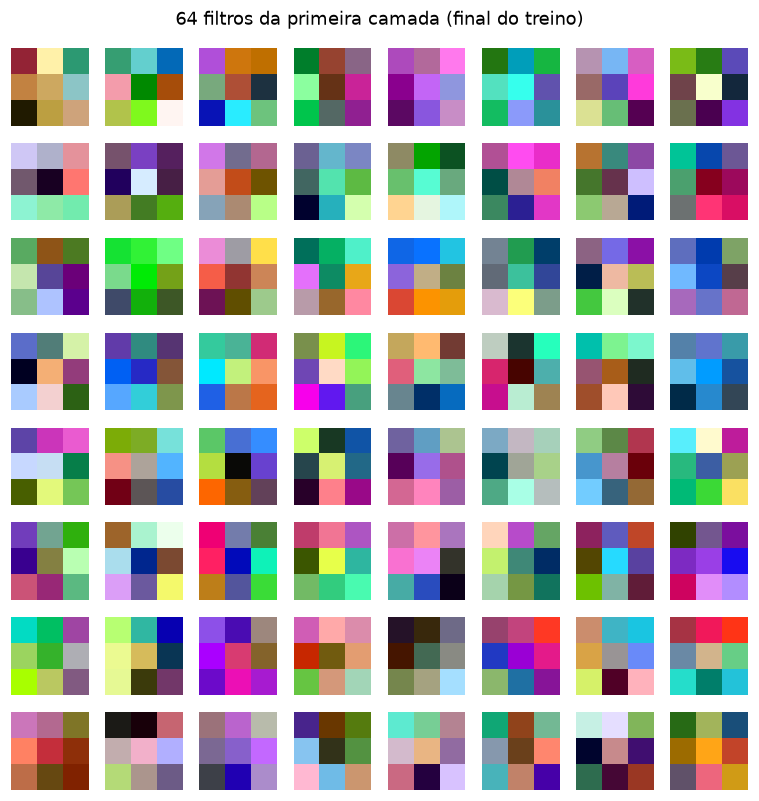

In [15]:
fig, eixos = plt.subplots(8, 8, figsize=(7, 7.4))
grafico_filtros(cnn.bloco1[0].weight, "64 filtros da primeira camada (final do treino)", eixos)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4a_filtros_final.png", bbox_inches="tight")
plt.show()

O que observar:
- Cada quadradinho é um filtro de 3x3 pixels. As cores mostram quanto o filtro "gosta" de vermelho, verde e azul em cada posição.
- Com só 3x3 pixels não dá para ver desenhos grandes. Mesmo assim, cerca de metade dos filtros tem um lado visivelmente mais claro que o outro. Dois exemplos fáceis de achar na figura: o da 7ª linha, 2ª coluna, com a coluna da esquerda amarelo-esverdeada e a da direita azul-escura, e o da 8ª linha, 7ª coluna, com a linha de cima bem clara e as duas de baixo escuras. Esse tipo de filtro detecta bordas, ou seja, lugares onde a imagem muda de claro para escuro.
- Outros filtros juntam cores opostas dentro do mesmo quadradinho, como verde ao lado de roxo ou laranja ao lado de azul. Eles respondem a mudanças de cor, e não de brilho: por exemplo, um objeto vermelho sobre um fundo azul.
- Alguns filtros são quase de uma cor só (por exemplo, bem verdes ou bem rosados). Eles respondem à cor da região, e não à forma.
- Isso combina com o que se sabe sobre CNNs: a primeira camada aprende coisas simples (bordas, cores e contrastes), e as camadas seguintes juntam essas peças em formas maiores.

## Filtros ao longo do treino
Mostramos os mesmos 16 filtros depois da 1ª época, da 5ª época e no final.

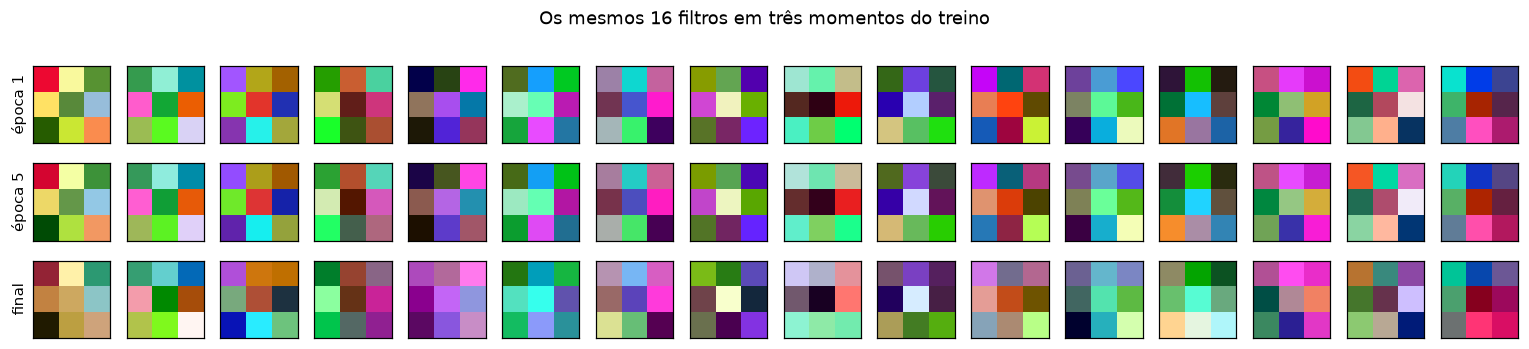

In [16]:
fig, eixos = plt.subplots(3, 16, figsize=(14, 3.3))
for linha, (nome, modelo) in enumerate({"época 1": cnn_epoca_1, "época 5": cnn_epoca_5, "final": cnn}.items()):
    filtros = filtros_para_imagem(modelo.bloco1[0].weight)
    for coluna in range(16):
        eixos[linha, coluna].imshow(filtros[coluna], interpolation="nearest")
        eixos[linha, coluna].set_xticks([])
        eixos[linha, coluna].set_yticks([])
    eixos[linha, 0].set_ylabel(nome)
plt.suptitle("Os mesmos 16 filtros em três momentos do treino")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4a_filtros_evolucao.png", bbox_inches="tight")
plt.show()

O que observar:
- Os filtros da época 1 e da época 5 são quase iguais. Nas primeiras épocas a rede ainda está ajustando as camadas finais e mexe pouco na primeira.
- Do meio para o fim do treino os filtros mudam bastante: as cores ficam diferentes e aparecem mais contrastes claro/escuro.
- Faz sentido com o OneCycle: a taxa de aprendizado ainda é pequena nas primeiras épocas e só fica grande por volta da época 12. É nessa fase que os pesos mais mudam.

## Quanto os filtros mudaram
Para cada filtro, medimos a distância entre os pesos no final e os pesos depois da 1ª e da 5ª época (quanto maior, mais o filtro mudou).

In [17]:
pesos_final = cnn.bloco1[0].weight.detach()
mudanca = pd.DataFrame({
    "da época 1 até o final": (pesos_final - cnn_epoca_1.bloco1[0].weight.detach()).flatten(1).norm(dim=1).cpu().numpy(),
    "da época 5 até o final": (pesos_final - cnn_epoca_5.bloco1[0].weight.detach()).flatten(1).norm(dim=1).cpu().numpy(),
})
mudanca.describe().loc[["mean", "min", "max"]].round(3)

,da época 1 até o final,da época 5 até o final
mean,0.640,0.600
min,0.401,0.386
max,0.972,0.930


A tabela confirma o que vimos nas imagens. A distância média entre os filtros finais e os da época 1 (0,64) é quase igual à distância até os da época 5 (0,60). Ou seja, entre a época 1 e a 5 os filtros mudaram pouco, e a maior parte da mudança aconteceu depois da época 5. Todos os filtros mudaram (o menor valor é 0,39): nenhum ficou parado com os pesos do começo.

## O que cada filtro destaca em uma imagem
Para entender melhor os filtros, aplicamos a primeira camada em uma imagem e mostramos a resposta de 16 filtros.

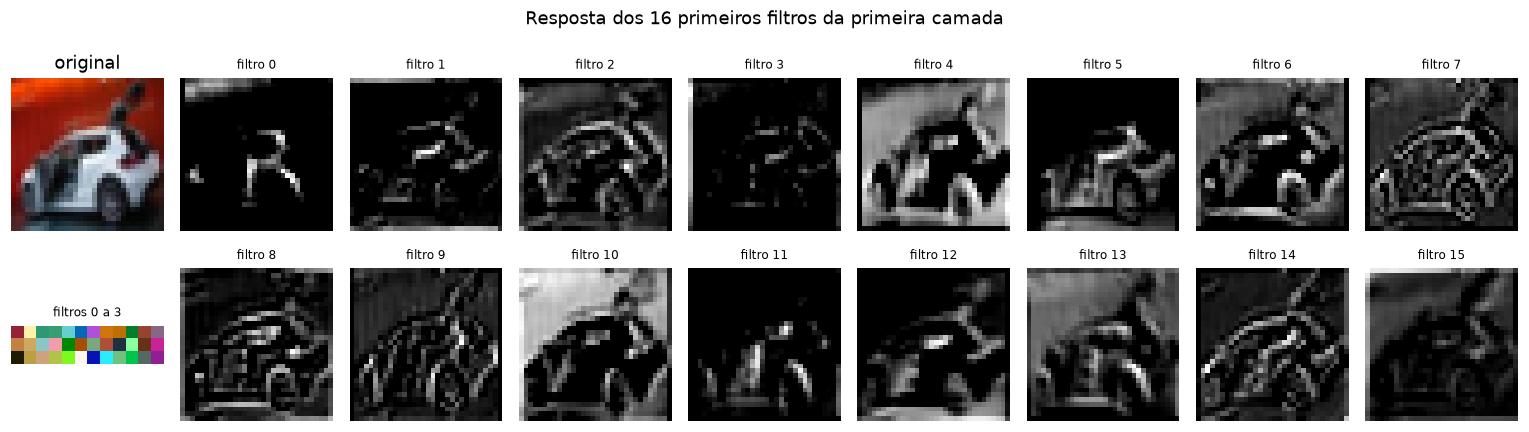

In [18]:
indice_exemplo = int(np.where(classes_teste == 1)[0][0])  # primeiro automóvel do teste
respostas = capturar_ativacoes(cnn, cnn.bloco1[2], X_teste[indice_exemplo:indice_exemplo + 1])[0]

fig, eixos = plt.subplots(2, 9, figsize=(14, 4.2))
eixos[0, 0].imshow(imagens_teste[indice_exemplo])
eixos[0, 0].set_title("original")
filtros_final = filtros_para_imagem(cnn.bloco1[0].weight)
for k in range(16):
    eixo = eixos[k // 8, 1 + k % 8]
    eixo.imshow(respostas[k].cpu().numpy(), cmap="gray")
    eixo.set_title(f"filtro {k}", fontsize=8)
eixos[1, 0].imshow(np.concatenate([filtros_final[k] for k in range(4)], axis=1), interpolation="nearest")
eixos[1, 0].set_title("filtros 0 a 3", fontsize=8)
for eixo in eixos.flat:
    eixo.axis("off")
plt.suptitle("Resposta dos 16 primeiros filtros da primeira camada")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4a_respostas_filtros.png", bbox_inches="tight")
plt.show()

O que observar (claro = o filtro respondeu forte, escuro = não respondeu):
- Vários filtros (por exemplo, 2, 7, 8, 9 e 14) desenham o contorno do carro: rodas, janelas e a borda da lataria. São detectores de borda.
- Outros respondem a regiões inteiras: o filtro 4 acende no fundo vermelho e o filtro 10 no fundo e no chão, enquanto o carro branco fica escuro. São filtros de cor.
- O filtro 0 quase não responde: só acende em uma estrutura fina no meio da imagem e em uma faixa no alto. É um detalhe bem específico de cor e brilho.
- Juntos, esses 64 mapas são a "matéria-prima" que as próximas camadas usam para reconhecer o objeto.

---
# Item b: mapas de ativação de uma camada intermediária

Usamos a saída do bloco 2 da CNN (depois da segunda convolução e da ReLU). Nesse ponto a imagem já foi reduzida para 16 x 16 e existem 128 mapas, um para cada filtro. Essa camada fica no meio da rede: ela já combina bordas e cores em padrões mais complexos, mas ainda guarda onde as coisas estão na imagem.

## Escolhendo as imagens
Pegamos a primeira imagem de teste que a rede acertou de seis classes diferentes.

In [19]:
previstos, probabilidades = prever(cnn, X_teste)
classes_escolhidas = ["avião", "automóvel", "pássaro", "gato", "cavalo", "navio"]
indices_ativacao = []
for nome in classes_escolhidas:
    c = CLASSES.index(nome)
    indices_ativacao.append(int(np.where((classes_teste == c) & (previstos == c))[0][0]))
print("Índices escolhidos:", indices_ativacao)

camada_intermediaria = cnn.bloco2[5]  # ReLU depois da segunda convolução do bloco 2
ativacoes = capturar_ativacoes(cnn, camada_intermediaria, X_teste[indices_ativacao])
print("Formato das ativações:", tuple(ativacoes.shape))

Índices escolhidos: [3, 6, 25, 0, 13, 1]
Formato das ativações: (6, 128, 16, 16)


## Imagem 1: avião

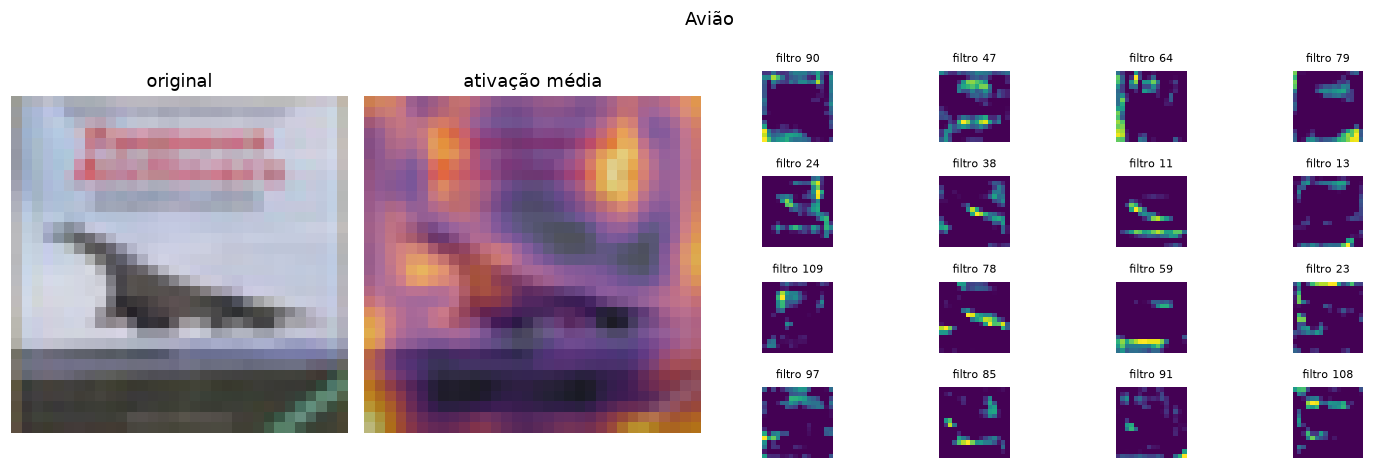

In [20]:
mostrar_ativacoes(imagens_teste[indices_ativacao[0]], ativacoes[0], "Avião", arquivo="4b_ativacoes_aviao.png")

O que observar:
- Os mapas mais ativos seguem linhas diagonais e horizontais (filtros 38, 11 e 78): é o formato da asa do avião.
- A ativação média também fica forte na placa com texto, no alto da imagem, e nas bordas. A camada intermediária ainda responde a qualquer contorno marcado, não só ao avião.
- O céu claro e liso quase não ativa nada.

## Imagem 2: automóvel

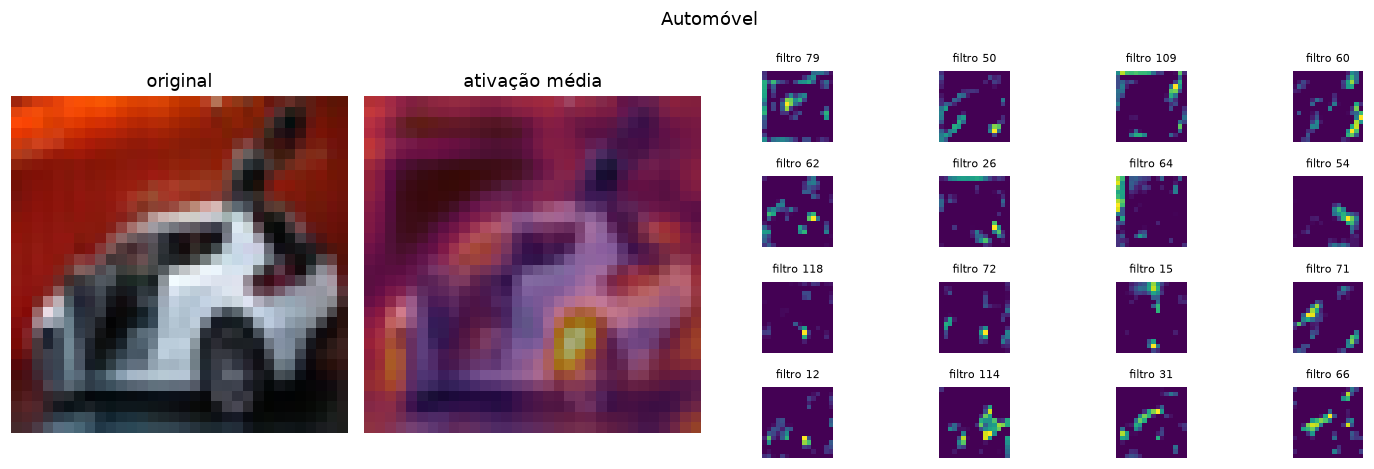

In [21]:
mostrar_ativacoes(imagens_teste[indices_ativacao[1]], ativacoes[1], "Automóvel", arquivo="4b_ativacoes_automovel.png")

O que observar:
- A ativação média é mais forte na roda da frente e na parte de baixo do carro (região amarela). Rodas são uma pista forte para "veículo".
- Vários mapas (filtros 31, 66 e 71) acendem em linhas diagonais, que acompanham o contorno da janela e do capô.
- O fundo vermelho, mesmo sendo bem chamativo, ativa pouco. A rede aprendeu a dar mais atenção ao objeto do que à cor do fundo.

## Imagem 3: pássaro

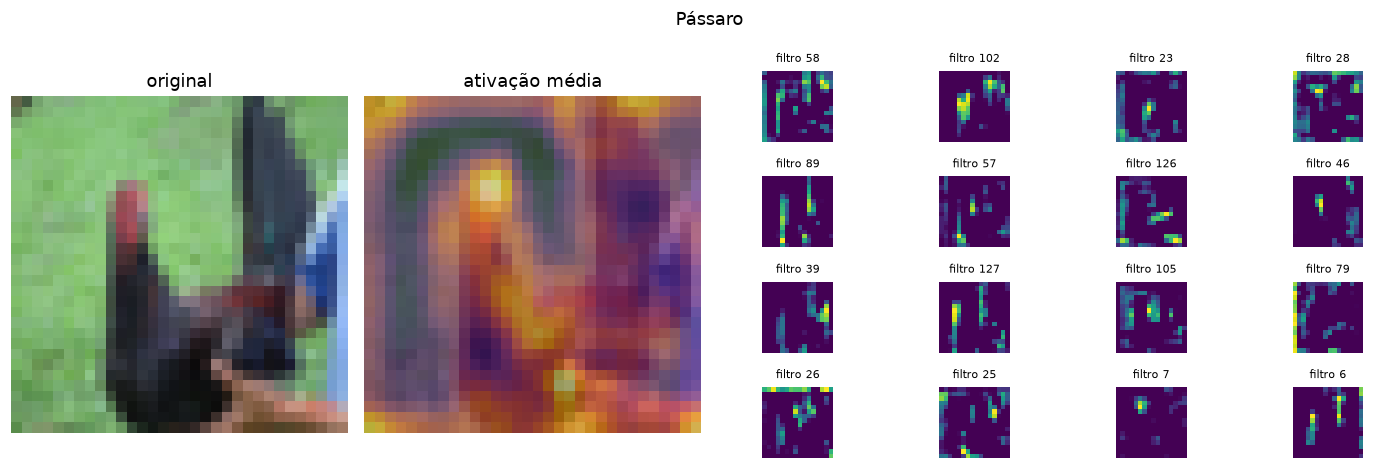

In [22]:
mostrar_ativacoes(imagens_teste[indices_ativacao[2]], ativacoes[2], "Pássaro", arquivo="4b_ativacoes_passaro.png")

O que observar:
- A região mais ativa é a cabeça vermelha do pássaro (ponto amarelo no alto do corpo) e o pescoço.
- Muitos mapas (filtros 89, 57, 127 e 6) respondem a linhas verticais, que acompanham o corpo e a cauda em pé.
- A grama verde do fundo fica escura, ou seja, quase não ativa.

## Imagem 4: gato

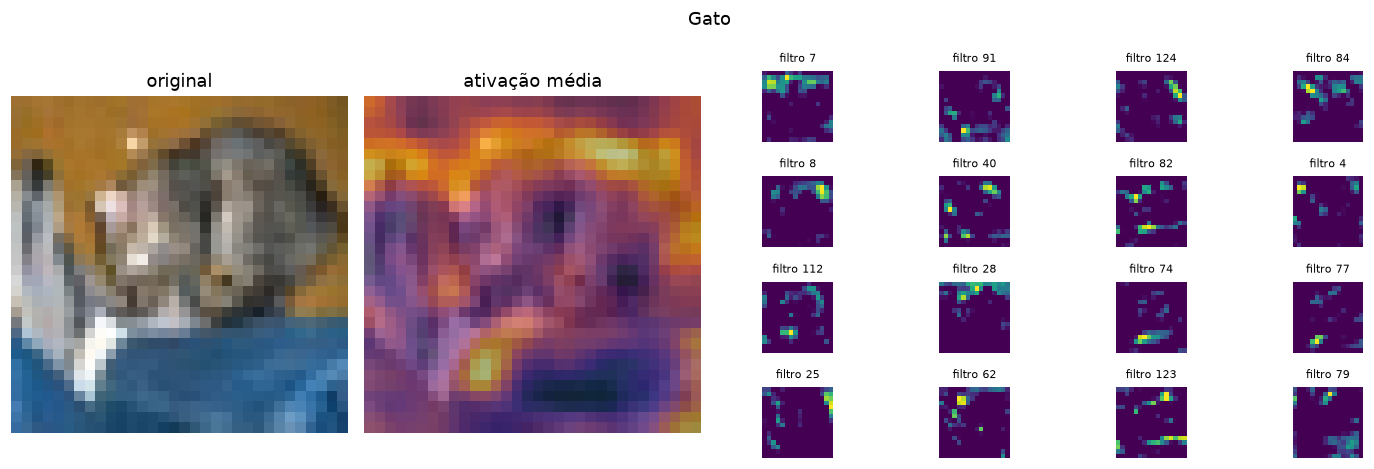

In [23]:
mostrar_ativacoes(imagens_teste[indices_ativacao[3]], ativacoes[3], "Gato", arquivo="4b_ativacoes_gato.png")

O que observar:
- Essa imagem é difícil: o gato tem uma pelagem com manchas que se mistura com o fundo.
- A ativação média é forte na linha do topo, onde o fundo laranja encontra a cabeça do gato, e em uma pata clara embaixo.
- Os mapas individuais são mais espalhados e com pontos isolados. Alguns acendem perto dos olhos e do rosto (filtros 82 e 40), mas não há uma forma tão clara como no carro ou no cavalo. Isso ajuda a entender por que gato é a classe mais difícil para a rede.

## Imagem 5: cavalo

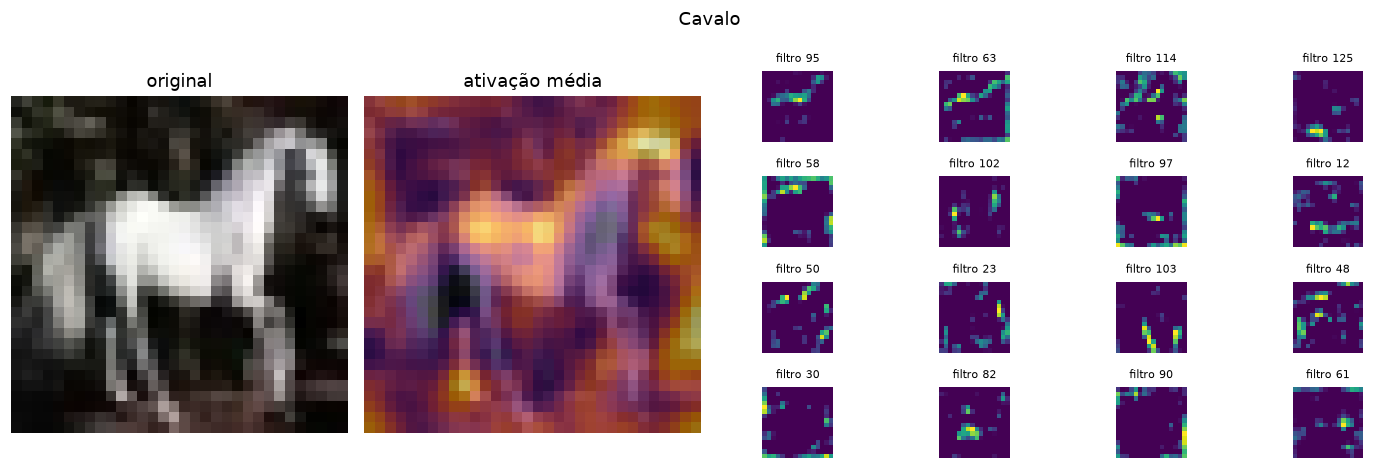

In [24]:
mostrar_ativacoes(imagens_teste[indices_ativacao[4]], ativacoes[4], "Cavalo", arquivo="4b_ativacoes_cavalo.png")

O que observar:
- A ativação média fica forte no corpo branco do cavalo e na cabeça, e fraca no fundo escuro.
- Alguns mapas (filtros 103 e 102) acendem em linhas verticais que lembram as pernas. Outros (filtros 95 e 63) seguem a linha das costas.
- Essa é a imagem em que o mapa médio mais lembra o formato do objeto: o contraste entre o cavalo claro e o fundo escuro facilita muito.

## Imagem 6: navio

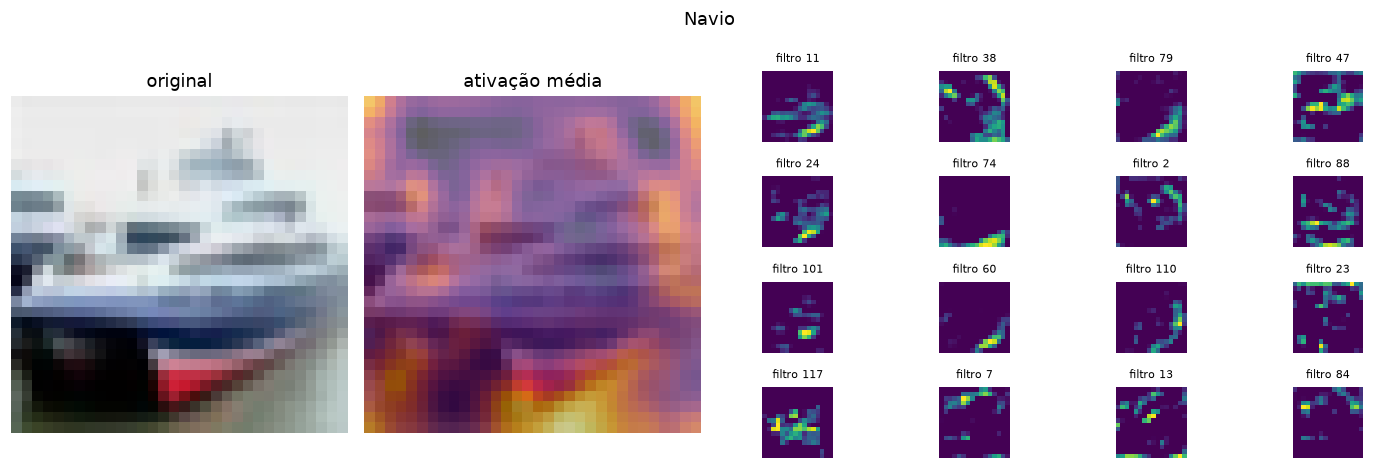

In [25]:
mostrar_ativacoes(imagens_teste[indices_ativacao[5]], ativacoes[5], "Navio", arquivo="4b_ativacoes_navio.png")

O que observar:
- A ativação média é mais forte na parte de baixo, no casco vermelho e na água.
- Vários mapas (filtros 79, 74 e 60) acendem em uma linha diagonal na parte de baixo: é a borda inclinada do casco.
- As janelas e a parte branca de cima ativam menos. Para a rede, o casco e a linha da água são as pistas mais importantes para "navio".

## Resumo da análise dos mapas de ativação

- Na camada intermediária, cada mapa responde a um padrão um pouco mais complexo que os filtros da primeira camada: linhas em certa direção, cantos, pedaços de contorno e manchas de cor.
- Na maioria das imagens, as regiões mais ativas ficam no objeto, e não no fundo: as rodas do carro, a cabeça do pássaro, o corpo do cavalo e o casco do navio.
- Fundos lisos (céu, grama, fundo vermelho) quase não ativam. Mas contornos fortes que não fazem parte do objeto também ativam, como a placa com texto na imagem do avião. A rede ainda não "sabe" o que é o objeto nessa camada; isso só acontece nas camadas finais.
- O gato é a imagem com ativações mais espalhadas e menos ligadas à forma do animal, o que combina com gato ser a classe mais difícil.

---
# Item c: exemplos certos e errados

## Exemplos classificados corretamente
Sorteamos uma imagem certa de cada uma de 10 classes.

Acertos: 9196 | Erros: 804


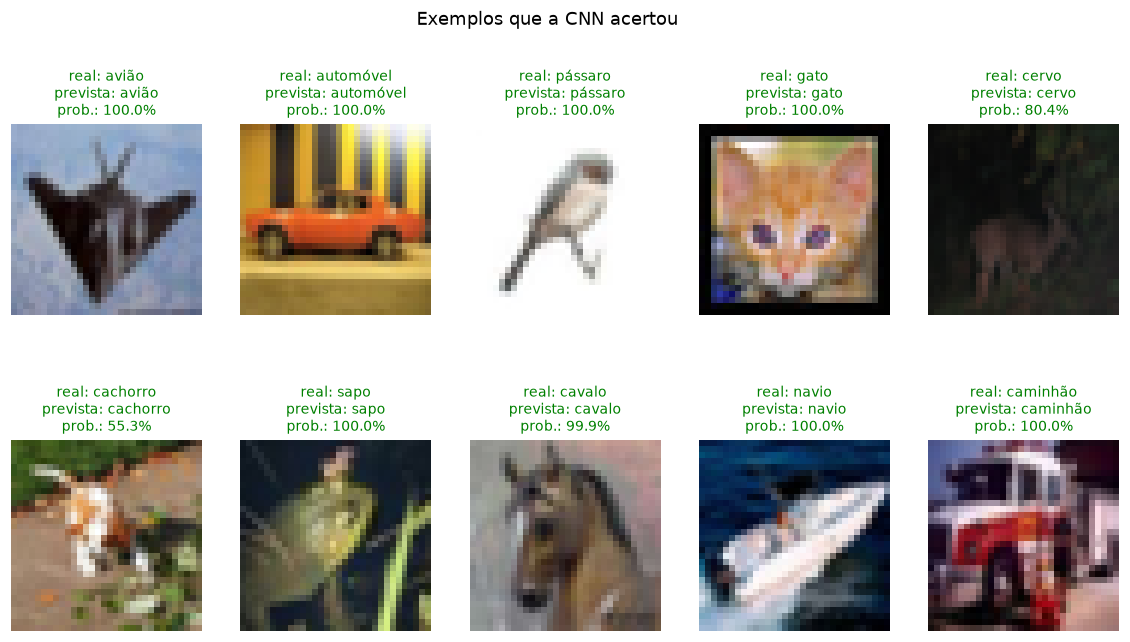

In [26]:
fixar_semente()
acertos = np.where(previstos == classes_teste)[0]
erros = np.where(previstos != classes_teste)[0]
print(f"Acertos: {len(acertos)} | Erros: {len(erros)}")

indices_certos = [int(np.random.choice(acertos[classes_teste[acertos] == c])) for c in range(10)]
grade_de_previsoes(indices_certos, imagens_teste, classes_teste, previstos, probabilidades,
                   "Exemplos que a CNN acertou", arquivo="4c_certos.png")

O que observar:
- Em 8 das 10 imagens a rede tem praticamente 100% de certeza. São imagens "típicas": o objeto aparece inteiro, centralizado e com bom contraste com o fundo.
- O cervo foi acertado com 80,4%: a foto é muito escura e o animal quase some no fundo.
- O cachorro foi acertado com só 55,3%: ele aparece de lado, pequeno e no meio de folhas. Mesmo acertando, a rede ficou em dúvida, provavelmente com gato.

## Exemplos classificados incorretamente
Sorteamos 10 imagens que a rede errou.

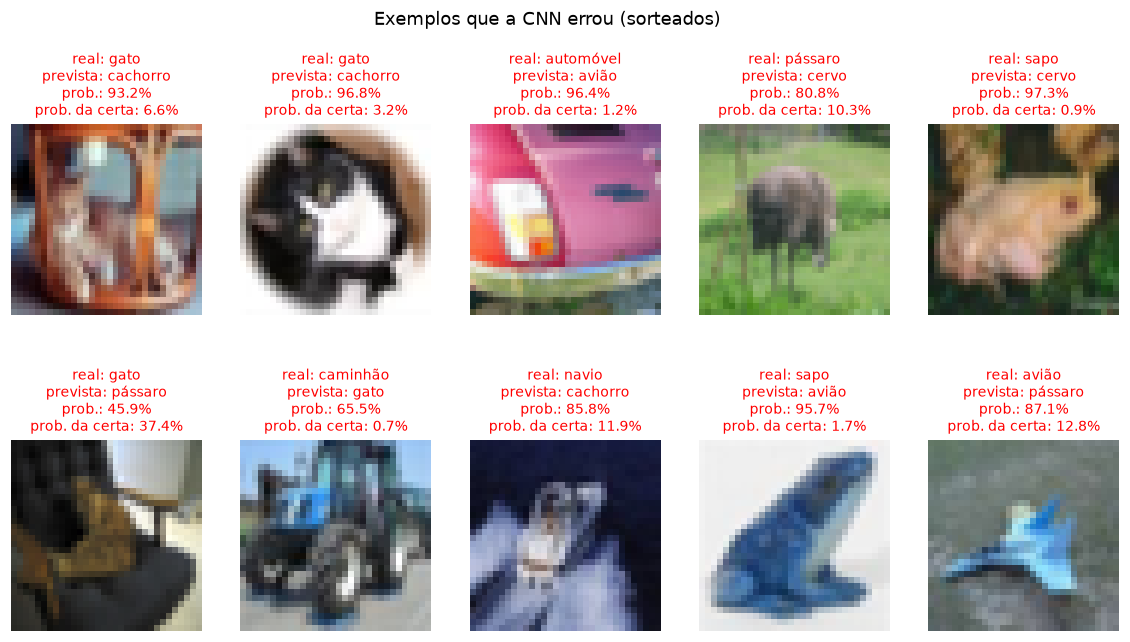

In [27]:
indices_errados = np.random.choice(erros, 10, replace=False)
grade_de_previsoes(indices_errados, imagens_teste, classes_teste, previstos, probabilidades,
                   "Exemplos que a CNN errou (sorteados)", arquivo="4c_errados.png")

O que observar:
- Os erros mais comuns são entre classes parecidas: gato vira cachorro (2 casos com mais de 90% de certeza), pássaro vira cervo e sapo vira cervo.
- Em vários erros a imagem é realmente difícil: o automóvel aparece só pela traseira bem de perto, o navio está escuro e borrado, e o gato aparece só parcialmente.
- Alguns erros vêm da cor ou do fundo: o sapo azul em fundo branco virou avião (fundo claro lembra céu) e o trator azul virou gato.
- Em muitos erros a probabilidade da classe certa é bem baixa (abaixo de 2%), ou seja, a rede nem considerou a resposta certa.

## Os erros mais "confiantes"
Agora as 10 imagens em que a rede errou dando a maior probabilidade para a classe errada.

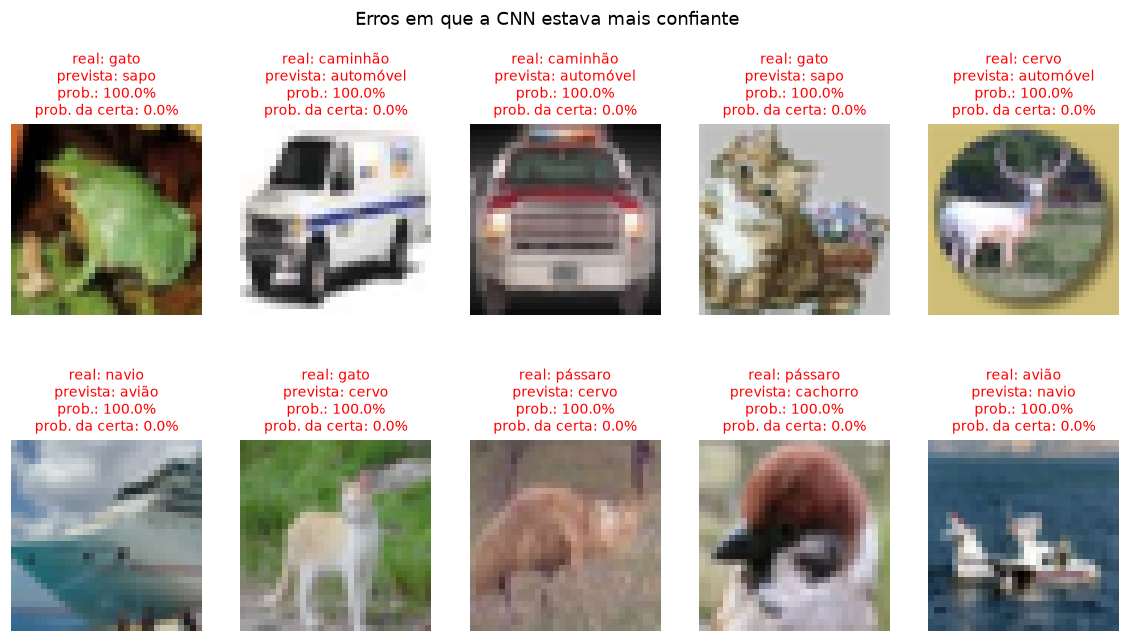

In [28]:
confianca = probabilidades.max(axis=1)
indices_confiantes = erros[np.argsort(confianca[erros])[::-1][:10]]
grade_de_previsoes(indices_confiantes, imagens_teste, classes_teste, previstos, probabilidades,
                   "Erros em que a CNN estava mais confiante", arquivo="4c_erros_confiantes.png")

O que observar:
- Nesses 10 erros a rede deu praticamente toda a probabilidade para a classe errada (100,0% depois do arredondamento para uma casa decimal) e praticamente zero para a classe certa.
- Alguns parecem erros de rótulo ou imagens ambíguas: o 1º "gato" é bem parecido com um sapo verde, e os dois "caminhões" são uma van e uma picape, que podem ser chamadas de automóvel.
- Outros mostram que a rede usa o fundo como pista: o avião pousado na água virou navio, e o navio com céu atrás virou avião.
- O cervo dentro de uma moldura redonda virou automóvel. A moldura não aparece no treino e confundiu a rede.
- Isso mostra uma limitação: a probabilidade da rede não é uma medida perfeita de certeza. Ela pode estar "certa de que está certa" e mesmo assim errar.

## Confiança da rede nos acertos e nos erros

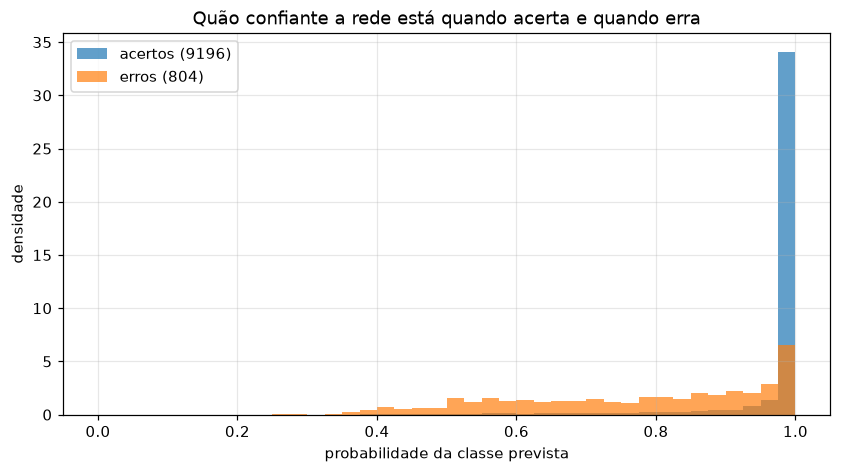

In [29]:
plt.figure(figsize=(9, 4.5))
plt.hist(confianca[acertos], bins=40, range=(0, 1), alpha=0.7, density=True, label=f"acertos ({len(acertos)})")
plt.hist(confianca[erros], bins=40, range=(0, 1), alpha=0.7, density=True, label=f"erros ({len(erros)})")
plt.xlabel("probabilidade da classe prevista")
plt.ylabel("densidade")
plt.title("Quão confiante a rede está quando acerta e quando erra")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(PASTA_FIGURAS / "4c_confianca.png", bbox_inches="tight")
plt.show()

O que observar:
- Quase todos os acertos (azul) estão encostados em 100% de probabilidade.
- Os erros (laranja) se espalham entre 30% e 100%. A maioria tem probabilidade bem menor que os acertos.
- Mas existe um grupo de erros perto de 100%: são os erros "confiantes" que vimos acima.

In [30]:
pd.DataFrame({
    "confiança média": [confianca[acertos].mean(), confianca[erros].mean()],
    "confiança mediana": [np.median(confianca[acertos]), np.median(confianca[erros])],
    "% com confiança acima de 90%": [(confianca[acertos] > 0.9).mean(), (confianca[erros] > 0.9).mean()],
}, index=["acertos", "erros"]).round(3)

,confiança média,confiança mediana,% com confiança acima de 90%
acertos,0.973,1.000,0.918
erros,0.774,0.811,0.342


Nos acertos, a confiança média é 97,3% e 91,8% deles têm mais de 90% de probabilidade. Nos erros, a confiança média cai para 77,4% e só 34,2% passam de 90%.

Então a probabilidade ajuda a separar acertos de erros: quando a rede está em dúvida, a chance de erro é bem maior. Mas não é perfeito, já que cerca de um terço dos erros ainda vem com mais de 90% de certeza.

Parte dessa confiança exagerada vem do overfitting leve que vimos na Questão 3 (99,3% de acurácia no treino contra 92,0% no teste). No treino a rede se acostumou a acertar quase tudo com muita certeza, e leva esse "excesso de certeza" para as imagens novas.

---
# Conclusão

Item a
- Os filtros da primeira camada aprenderam coisas simples: bordas (claro de um lado e escuro do outro), contrastes entre cores opostas e manchas de uma cor só.
- Entre a época 1 e a 5 eles mudam pouco. A maior parte da mudança acontece no meio do treino, quando a taxa de aprendizado do OneCycle está alta.

Item b
- Na camada intermediária, os mapas respondem a linhas, cantos e pedaços de contorno. Em geral as regiões mais ativas ficam no objeto (rodas, cabeça, corpo, casco), e o fundo liso quase não ativa.
- A imagem do gato teve as ativações mais espalhadas, o que ajuda a explicar por que gato é a classe mais difícil.

Item c
- A CNN acerta 9196 das 10000 imagens de teste (92,0%), quase sempre com probabilidade perto de 100%.
- Os erros acontecem em imagens difíceis (escuras, cortadas, de ângulo estranho), entre classes parecidas (gato e cachorro, caminhão e automóvel) e quando o fundo engana (avião sobre água, navio com céu).
- A rede é mais confiante quando acerta (97% em média) do que quando erra (77%). Mesmo assim, cerca de um terço dos erros vem com mais de 90% de certeza.